In [11]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

# =====================================
# CONFIGURACIÓN
# =====================================

LAT = 37.9922      # Murcia
LON = -1.1307

START = "20240101"
END = "20241231"

PARAMETERS = "T2M,PRECTOTCORR,RH2M,WS2M,ALLSKY_SFC_SW_DWN"

In [12]:

# =====================================
# DESCARGA DE DATOS NASA POWER
# =====================================

url = (
    "https://power.larc.nasa.gov/api/temporal/daily/point"
    f"?parameters={PARAMETERS}"
    "&community=AG"
    f"&latitude={LAT}"
    f"&longitude={LON}"
    f"&start={START}"
    f"&end={END}"
    "&format=JSON"
)

response = requests.get(url)
data = response.json()

In [13]:

# =====================================
# CONVERTIR A DATAFRAME
# =====================================

params = data["properties"]["parameter"]

df = pd.DataFrame({
    "fecha": pd.to_datetime(list(params["T2M"].keys())),
    "temperatura": list(params["T2M"].values()),
    "precipitacion": list(params["PRECTOTCORR"].values()),
    "humedad": list(params["RH2M"].values()),
    "viento": list(params["WS2M"].values()),
    "radiacion": list(params["ALLSKY_SFC_SW_DWN"].values())
})

# Eliminar valores faltantes NASA (-999)
df.replace(-999, pd.NA, inplace=True)

print(df.head())

       fecha  temperatura  precipitacion  humedad  viento  radiacion
0 2024-01-01        10.16           0.00    67.52    1.99       9.79
1 2024-01-02        10.87           0.00    54.11    1.64       8.96
2 2024-01-03        13.02           0.00    68.56    2.17      10.30
3 2024-01-04        13.85           0.29    77.05    1.53       5.34
4 2024-01-05        10.74           1.69    65.84    4.50       8.29


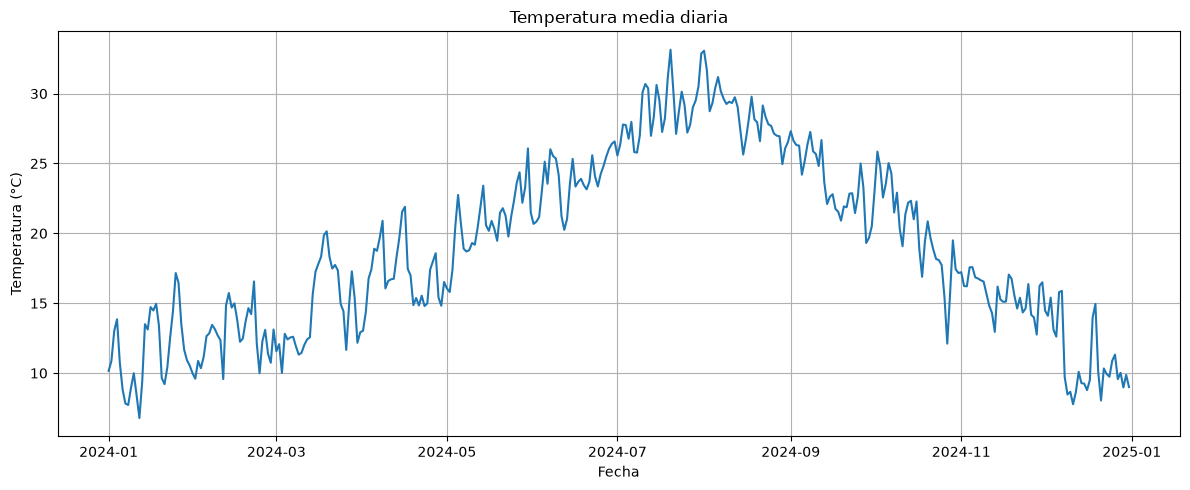

In [14]:

# =====================================
# GRÁFICO TEMPERATURA
# =====================================

plt.figure(figsize=(12, 5))
plt.plot(df["fecha"], df["temperatura"])
plt.title("Temperatura media diaria")
plt.xlabel("Fecha")
plt.ylabel("Temperatura (°C)")
plt.grid(True)
plt.tight_layout()
plt.show()

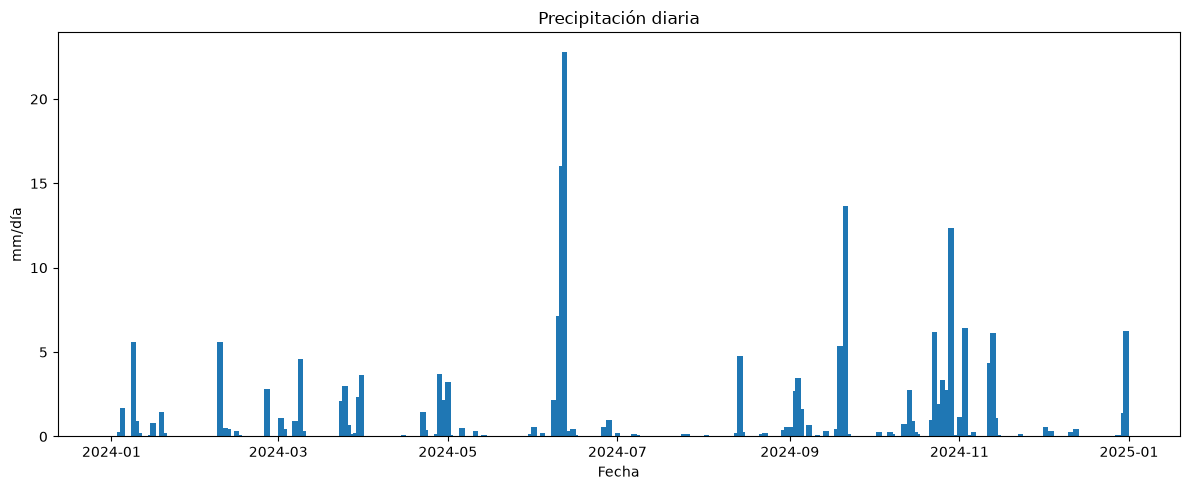

In [15]:

# =====================================
# GRÁFICO PRECIPITACIÓN
# =====================================

plt.figure(figsize=(12, 5))
plt.bar(df["fecha"], df["precipitacion"], width=2)
plt.title("Precipitación diaria")
plt.xlabel("Fecha")
plt.ylabel("mm/día")
plt.tight_layout()
plt.show()

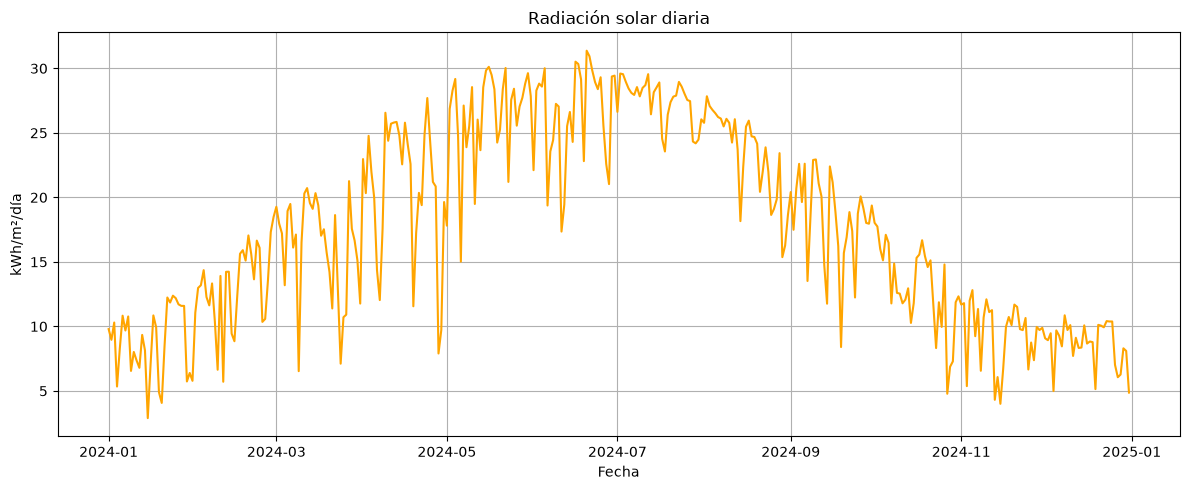

In [16]:

# =====================================
# GRÁFICO RADIACIÓN SOLAR
# =====================================

plt.figure(figsize=(12, 5))
plt.plot(df["fecha"], df["radiacion"], color="orange")
plt.title("Radiación solar diaria")
plt.xlabel("Fecha")
plt.ylabel("kWh/m²/día")
plt.grid(True)
plt.tight_layout()
plt.show()